<a href="https://colab.research.google.com/github/MMASirOwlbie/CNNProject-StarDetectionReproduction/blob/experiment%2Fconventional-vs-elunet/Conventional_vs_ELUnet_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

#paths
DRIVE_PROJECT = "/content/drive/MyDrive/CNNStarDetection"
REPO_DIR = "/content/CNNProject-StarDetectionReproduction"

DRIVE_DATA = os.path.join(DRIVE_PROJECT, "training_data")
LOCAL_DATA = os.path.join(
    REPO_DIR, "data_generation", "training_data"
)

#clone repository if it isn't already present
if not os.path.exists(REPO_DIR):
    !git clone -b experiment/conventional-vs-elunet https://github.com/MMASirOwlbie/CNNProject-StarDetectionReproduction.git {REPO_DIR}

#restore persistent datasets
if not os.path.exists(DRIVE_DATA):
    print("WARNING: No persistent dataset found in Google Drive.")
    print("Generate the datasets once, then back them up to DRIVE_DATA.")
elif not os.path.exists(LOCAL_DATA):
    #symlink for dir acc
    os.symlink(DRIVE_DATA, LOCAL_DATA)
    print("Connected repository to persistent Drive datasets.")
else:
    print("training_data already exists in the repository.")

#Confirm setup
print("\nProject ready.")
print("Repository:", REPO_DIR)
print("Drive dataset:", DRIVE_DATA)
print("Local dataset path:", LOCAL_DATA)

if os.path.exists(LOCAL_DATA):
    for folder in ["train_raw", "val_raw", "test_raw"]:
        folder_path = os.path.join(LOCAL_DATA, folder)
        count = len([
            f for f in os.listdir(folder_path)
            if f.endswith(".npy")
        ]) if os.path.isdir(folder_path) else 0
        print(f"{folder}: {count} files")

%pip install thop

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
training_data already exists in the repository.

Project ready.
Repository: /content/CNNProject-StarDetectionReproduction
Drive dataset: /content/drive/MyDrive/CNNStarDetection/training_data
Local dataset path: /content/CNNProject-StarDetectionReproduction/data_generation/training_data
train_raw: 300 files
val_raw: 100 files
test_raw: 100 files


In [ ]:
import os
import sys

REPO_DIR = "/content/CNNProject-StarDetectionReproduction"

# Confirm the repository exists in this runtime
if not os.path.isdir(REPO_DIR):
    raise FileNotFoundError(
        f"Repository not found at {REPO_DIR}. Run your startup cell first."
    )

# Make the repository root available to Python
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

os.chdir(REPO_DIR)

print("Working directory:", os.getcwd())
print("Repository on Python path:", REPO_DIR in sys.path)
print("Training directory exists:", os.path.isdir("training"))

Working directory: /content/CNNProject-StarDetectionReproduction
Repository on Python path: True
Training directory exists: True


In [ ]:

%cd /content

!rm -rf CNNProject-StarDetectionReproduction

!git clone -b experiment/conventional-vs-elunet \
    https://github.com/MMASirOwlbie/CNNProject-StarDetectionReproduction.git

%cd /content/CNNProject-StarDetectionReproduction

!git status

/content
Cloning into 'CNNProject-StarDetectionReproduction'...
remote: Enumerating objects: 408, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 408 (delta 13), reused 4 (delta 1), pack-reused 377 (from 1)
Receiving objects: 100% (408/408), 235.53 MiB | 27.65 MiB/s, done.
Resolving deltas: 100% (113/113), done.
/content/CNNProject-StarDetectionReproduction
On branch experiment/conventional-vs-elunet
Your branch is up to date with 'origin/experiment/conventional-vs-elunet'.

nothing to commit, working tree clean


In [ ]:
%cd /content/CNNProject-StarDetectionReproduction/data_generation

!gdown 1_uvcg0AcxmWhJoxbO5dH1Y51mUlNPW3R -O dark_frames_straylight.zip

/content/CNNProject-StarDetectionReproduction/data_generation
Downloading...
From (original): https://drive.google.com/uc?id=1_uvcg0AcxmWhJoxbO5dH1Y51mUlNPW3R
From (redirected): https://drive.google.com/uc?id=1_uvcg0AcxmWhJoxbO5dH1Y51mUlNPW3R&confirm=t&uuid=8a64b5a8-433e-45e6-adb0-eb7b9c49f473
To: /content/CNNProject-StarDetectionReproduction/data_generation/dark_frames_straylight.zip
100% 408M/408M [00:04<00:00, 87.7MB/s]


In [ ]:
%cd /content/CNNProject-StarDetectionReproduction

!mv /content/dark_frames_straylight.zip ./data_generation/

%cd /content/CNNProject-StarDetectionReproduction/data_generation

!unzip -q -o dark_frames_straylight.zip

from main_generate_data import star_img_sim, generate_and_save

sim_obj = star_img_sim(500, "./dark_frames_straylight")

/content/CNNProject-StarDetectionReproduction
mv: cannot stat '/content/dark_frames_straylight.zip': No such file or directory
/content/CNNProject-StarDetectionReproduction/data_generation
num of dark frames currently in folder = 1000


In [ ]:
#create the directory for generated datasets
!mkdir -p training_data

#gnera the fixed experimental datasets
generate_and_save(sim_obj, 300, "train", "./training_data")
generate_and_save(sim_obj, 100, "val", "./training_data")
generate_and_save(sim_obj, 100, "test", "./training_data")

current progress = 1 out of 300. time = 2.71 s
current progress = 2 out of 300. time = 8.58 s
current progress = 3 out of 300. time = 4.06 s
current progress = 4 out of 300. time = 5.85 s
current progress = 5 out of 300. time = 4.55 s
current progress = 6 out of 300. time = 5.68 s
current progress = 7 out of 300. time = 6.87 s
current progress = 8 out of 300. time = 4.47 s
current progress = 9 out of 300. time = 4.46 s
current progress = 10 out of 300. time = 6.45 s
current progress = 11 out of 300. time = 5.46 s
current progress = 12 out of 300. time = 3.20 s
current progress = 13 out of 300. time = 7.55 s
current progress = 14 out of 300. time = 4.63 s
current progress = 15 out of 300. time = 7.72 s
current progress = 16 out of 300. time = 4.07 s
current progress = 17 out of 300. time = 4.88 s
current progress = 18 out of 300. time = 10.23 s
current progress = 19 out of 300. time = 4.85 s
current progress = 20 out of 300. time = 5.49 s
current progress = 21 out of 300. time = 5.43 s


0

In [ ]:
%pip install thop

In [ ]:
%cd /content/CNNProject-StarDetectionReproduction/training

import os
os.makedirs("./models", exist_ok=True)
os.makedirs("./saved_models", exist_ok=True)

!python training_stepLR.py --ep 30 --batch_size 1 --trial 1

/content/CNNProject-StarDetectionReproduction/training
I0000 00:00:1792427323.321933    7129 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792427325.866507    7129 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
model ELUnet is created!
epoch = 0, train_dist_loss = 0.02042202396070934, train_seg_loss = 0.21344091162085532, val_dist_loss = 0.026482338090863776, val_seg_loss = 0.09112340055406093, lr = 0.001, 277.2011103630066 s per epoch
model saved
epoch = 1, train_dist_loss = 0.005869207403811742, train_seg_loss = 0.05383702005570134, val_dist_loss = 0.012214677644369658, val_seg_loss = 0.03649113653227687, lr = 0.001, 42.86734127998352 s per epoch
epoch = 2, train_dist_loss = 0.003351656783367313, train_seg_loss = 0.02

In [ ]:
from pathlib import Path

checkpoint = Path(
    "/content/CNNProject-StarDetectionReproduction/training/models/latest_model.pt"
)

if checkpoint.exists():
    print("Model saved successfully!")
    print(f"Size: {checkpoint.stat().st_size / (1024**2):.2f} MB")
else:
    print("Checkpoint not found. Check the training log for errors.")

Model saved successfully!
Size: 3.12 MB


In [ ]:
from pathlib import Path
import shutil

source = Path(
    "/content/CNNProject-StarDetectionReproduction/training/models/latest_model.pt"
)
drive_dir = Path("/content/drive/MyDrive/CNNStarDetection/checkpoints")
drive_dir.mkdir(parents=True, exist_ok=True)

destination = drive_dir / "latest_model.pt"
shutil.copy2(source, destination)

print("Backup exists:", destination.exists())
print("Backup size:", round(destination.stat().st_size / (1024**2), 2), "MB")

Backup exists: True
Backup size: 3.12 MB


In [ ]:
from pathlib import Path

REPO = Path("/content/CNNProject-StarDetectionReproduction")
TRAIN_DIR = REPO / "training"
DATA_DIR = REPO / "data_generation" / "training_data"
CHECKPOINT = Path(
    "/content/drive/MyDrive/CNNStarDetection/checkpoints/latest_model.pt"
)

print("Checkpoint exists:", CHECKPOINT.exists())
print("Test images:", len(list((DATA_DIR / "test_raw").glob("*.npy"))))
print("Evaluation script exists:", (TRAIN_DIR / "evaluation.py").exists())

Checkpoint exists: True
Test images: 100
Evaluation script exists: True


In [ ]:
#EVALUATION
#Adapted from the official repository.

%cd /content/CNNProject-StarDetectionReproduction/training
import torch
import numpy as np
from math import sqrt
from scipy.linalg import lstsq
from scipy import ndimage
from torch.utils import data
from torchvision.transforms import Normalize

from data_load import StarDataSet
from neural_net.elunet import ELUnet


device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


#Trilateration centroid estimation

def trilateration_centroid(
    dist_map,
    seg_map,
    radius,
    pixel_size=6 / 1000.0
):
    """
    Estimate star centroids using the predicted distance map
    and segmentation map.

    Adapted from the official repository evaluation.py.
    """

    dist_map = dist_map.astype("float64")
    seg_map = seg_map.astype("float64")

    image_height = dist_map.shape[0]
    image_width = dist_map.shape[1]

    centroid_est = []

    threshold = 2 #official threshold

    dist_min = ndimage.minimum_filter(
        dist_map,
        size=(10, 10),
        mode="constant"
    )

    mask = (dist_map == dist_min)

    for current_row in range(image_height):

        for current_col in range(image_width):

            if (
                dist_map[current_row, current_col] <= threshold
                and seg_map[current_row, current_col] > 0
                and mask[current_row, current_col]
            ):

                x_i = []
                y_i = []
                r_i = []

                for row_shift in range(-radius, radius + 1):

                    for col_shift in range(-radius, radius + 1):

                        row = current_row + row_shift
                        col = current_col + col_shift

                        try:

                            if seg_map[row, col] > 0:


                                u = col + 0.5
                                v = row + 0.5

                                r_i.append(dist_map[row, col])
                                x_i.append(u)
                                y_i.append(v)

                                seg_map[row, col] = 0

                        except IndexError:
                            pass

                if len(x_i) < 2:
                    continue

                n = len(x_i)

                x_n = x_i[-1]
                y_n = y_i[-1]
                r_n = r_i[-1]

                A = np.zeros((n - 1, 2))

                for i in range(n - 1):

                    A[i, 0] = 2 * (x_n - x_i[i])
                    A[i, 1] = 2 * (y_n - y_i[i])

                B = np.zeros(n - 1)

                for i in range(n - 1):

                    B[i] = (
                        r_i[i] ** 2
                        - r_n ** 2
                        - x_i[i] ** 2
                        - y_i[i] ** 2
                        + x_n ** 2
                        + y_n ** 2
                    )

                #Least-squares trilateration
                x = lstsq(
                    A,
                    B,
                    lapack_driver="gelsy"
                )

                u = x[0][0] * pixel_size
                v = x[0][1] * pixel_size

                centroid_est.append([u, v])

    return centroid_est


#Centroid error cal

def compute_centroid_error(
    centroid_real,
    centroid_est,
    pixel_size
):
    """
    Calculate centroid estimation error.

    Returns:
        rms
        true_positive
        false_positive
        false_negative
        num_stars_real
        error_list
    """

    error_list = []

    num_stars_real = len(centroid_real)
    num_stars_est = len(centroid_est)

    for i in range(num_stars_real):

        u_real = centroid_real[i][0]
        v_real = centroid_real[i][1]
        mag_real = centroid_real[i][2]

        for j in range(len(centroid_est)):

            u_est = centroid_est[j][0]
            v_est = centroid_est[j][1]

            err = sqrt(
                (u_real - u_est) ** 2
                + (v_real - v_est) ** 2
            )

            # matching threshold
            if err < pixel_size:

                error_list.append([
                    err / pixel_size,
                    mag_real
                ])

                centroid_est.pop(j)

                break

    #RMS error
    n = len(error_list)

    rms = 0

    for err, mag in error_list:
        rms += err * err

    try:
        rms = sqrt(rms / n)
    except ZeroDivisionError:
        pass

    true_positive = n
    false_positive = num_stars_est - true_positive
    false_negative = num_stars_real - true_positive

    return (
        rms,
        true_positive,
        false_positive,
        false_negative,
        num_stars_real,
        error_list
    )


# Evaluation

def evaluate_model(model, test_dataloader, mean, std, device):

    model.eval()
    model = model.to(device)

    #Official values
    pixel_size = 6 / 1000.0  # mm
    radius = 5

    rms_total = 0.0

    true_positive_total = 0
    false_positive_total = 0
    false_negative_total = 0
    true_stars_total = 0

    error_mag_list = []
    real_star_magnitude = []

    #Iterate through test set

    with torch.no_grad():

        for counter, batch in enumerate(test_dataloader, 0):

            img, dist_map, seg_map, centroid_real = batch

            img = img.to(device)

            # Our custom collate function returns centroid_real
            # as a list containing the batch entries.
            # Official evaluation uses batch_size=1.
            centroid_real = centroid_real[0].numpy()

            real_star_magnitude.extend(
                centroid_real[:, 2]
            )

            # Neural network prediction

            normalized_img = Normalize(
                mean,
                std
            )(img)

            prediction = model(normalized_img)

            # Model output:
            # prediction.shape = batch, 2, height, width]
            # channel 0 = segmentation
            # channel 1 = distance map

            seg_prediction = (
                1.0
                * (
                    torch.sigmoid(
                        prediction[0][0]
                    ) > 0.5
                )
            )

            seg_prediction = (
                seg_prediction
                .detach()
                .cpu()
                .numpy()
            )

            dist_prediction = prediction[0][1]

            dist_prediction = (
                dist_prediction
                .detach()
                .cpu()
                .numpy()
            )

            #centroids

            centroid_est = trilateration_centroid(
                dist_prediction.copy(),
                seg_prediction.copy(),
                radius,
                pixel_size
            )

            #error

            (
                rms,
                true_positive,
                false_positive,
                false_negative,
                num_stars_real,
                error_list
            ) = compute_centroid_error(
                centroid_real,
                centroid_est.copy(),
                pixel_size
            )

            rms_total += rms * rms

            true_positive_total += true_positive
            false_positive_total += false_positive
            false_negative_total += false_negative
            true_stars_total += num_stars_real

            error_mag_list.extend(error_list)

            print(
                f"Evaluation: "
                f"{counter + 1}/{len(test_dataloader)}"
            )

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    #metrics

    rms_total = sqrt(
        rms_total / len(test_dataloader)
    )

    true_stars_total /= len(test_dataloader)

    precision = (
        true_positive_total
        / (
            true_positive_total
            + false_positive_total
        )
    )

    recall = (
        true_positive_total
        / (
            true_positive_total
            + false_negative_total
        )
    )

    F1 = (
        2 * precision * recall
        / (precision + recall)
    )

    result = [
        rms_total,
        precision,
        recall,
        F1,
        true_stars_total
    ]

    return (
        result,
        error_mag_list,
        real_star_magnitude
    )


#LOAD TEST DATA

mean = [25.36114133]
std = [44.31162568]


#dataset

test_dataset = StarDataSet(
    split="test",
    norm=False,
    mean=mean,
    std=std
)


#DataLoader

test_loader = data.DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

print("Test images:", len(test_dataset))

#LOAD MODEL

model = ELUnet(
    in_channels=1,
    out_channels=2
).to(device)

checkpoint_path = (
    "/content/drive/MyDrive/CNNStarDetection/"
    "checkpoints/latest_model.pt"
)

state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model.eval()

print("Loaded checkpoint:", checkpoint_path)

#Verify output

with torch.no_grad():

    sample_batch = next(iter(test_loader))

    sample_images = sample_batch[0].to(device)

    prediction = model(sample_images)

print("Input shape :", sample_images.shape)
print("Output shape:", prediction.shape)


#eval

result, error_mag_list, real_star_magnitude = evaluate_model(
    model,
    test_loader,
    mean,
    std,
    device
)


#resUlts

rms = result[0]
precision = result[1]
recall = result[2]
F1 = result[3]
average_true_stars = result[4]

print("\n" + "=" * 60)
print("ML MODEL EVALUATION")
print("=" * 60)

print(
    f"RMS centroid error : {rms:.6f} pixels"
)

print(
    f"Precision           : {precision:.6f}"
)

print(
    f"Recall              : {recall:.6f}"
)

print(
    f"F1                  : {F1:.6f}"
)

print(
    f"Average true stars  : {average_true_stars:.2f}"
)

print("=" * 60)

/content/CNNProject-StarDetectionReproduction/training
Using device: cuda:0
Test images: 100
Loaded checkpoint: /content/drive/MyDrive/CNNStarDetection/checkpoints/latest_model.pt
Input shape : torch.Size([1, 1, 480, 640])
Output shape: torch.Size([1, 2, 480, 640])
Evaluation: 1/100
Evaluation: 2/100
Evaluation: 3/100
Evaluation: 4/100
Evaluation: 5/100
Evaluation: 6/100
Evaluation: 7/100
Evaluation: 8/100
Evaluation: 9/100
Evaluation: 10/100
Evaluation: 11/100
Evaluation: 12/100
Evaluation: 13/100
Evaluation: 14/100
Evaluation: 15/100
Evaluation: 16/100
Evaluation: 17/100
Evaluation: 18/100
Evaluation: 19/100
Evaluation: 20/100
Evaluation: 21/100
Evaluation: 22/100
Evaluation: 23/100
Evaluation: 24/100
Evaluation: 25/100
Evaluation: 26/100
Evaluation: 27/100
Evaluation: 28/100
Evaluation: 29/100
Evaluation: 30/100
Evaluation: 31/100
Evaluation: 32/100
Evaluation: 33/100
Evaluation: 34/100
Evaluation: 35/100
Evaluation: 36/100
Evaluation: 37/100
Evaluation: 38/100
Evaluation: 39/100
Ev

In [ ]:
import os
import glob
import shutil

REPO_ROOT = "/content/CNNProject-StarDetectionReproduction"
DATA_DIR = os.path.join(REPO_ROOT, "data_generation", "training_data")

# Each sample has four corresponding files.
folders = [
    "train_raw",
    "train_centroid",
    "train_dist_map",
    "train_seg_map",
]

# Identify samples by the final part of their filename.
def sample_id(path):
    return os.path.basename(path).rsplit("_", 1)[-1].removesuffix(".npy")

files_by_folder = {
    folder: sorted(glob.glob(os.path.join(DATA_DIR, folder, "*.npy")))
    for folder in folders
}

# Verify that all four folders contain matching samples.
ids_by_folder = {
    folder: {sample_id(path) for path in paths}
    for folder, paths in files_by_folder.items()
}

assert all(ids == ids_by_folder[folders[0]]
           for ids in ids_by_folder.values()), (
    "Sample IDs do not match across folders. Stop and inspect the filenames."
)

all_ids = sorted(ids_by_folder[folders[0]],
                 key=lambda x: int(x) if x.isdigit() else x)

assert len(all_ids) >= 300, f"Expected 300 samples, found {len(all_ids)}"

# Nested subsets: the 100-image set is included in the 200-image set.
for n in [100, 200]:
    subset_dir = os.path.join(
        REPO_ROOT, "data_generation", f"training_data_{n}"
    )

    for folder in folders:
        os.makedirs(os.path.join(subset_dir, folder), exist_ok=True)

    for sid in all_ids[:n]:
        for folder in folders:
            matches = [
                p for p in files_by_folder[folder]
                if sample_id(p) == sid
            ]
            assert len(matches) == 1, (folder, sid, matches)

            destination = os.path.join(
                subset_dir, folder, os.path.basename(matches[0])
            )
            shutil.copy2(matches[0], destination)

    print(f"Created {n}-image subset: {subset_dir}")

print("Original training dataset remains unchanged.")

Created 100-image subset: /content/CNNProject-StarDetectionReproduction/data_generation/training_data_100
Created 200-image subset: /content/CNNProject-StarDetectionReproduction/data_generation/training_data_200
Original training dataset remains unchanged.


In [ ]:
import os

BASE = "/content/CNNProject-StarDetectionReproduction/data_generation"
ORIGINAL = os.path.join(BASE, "training_data")
BACKUP = os.path.join(BASE, "training_data_original")
SMALL = os.path.join(BASE, "training_data_100")

assert os.path.isdir(ORIGINAL), "Original training_data folder not found."
assert os.path.isdir(SMALL), "100-image dataset not found."
assert not os.path.exists(BACKUP), "Backup path already exists; stop and inspect."

os.rename(ORIGINAL, BACKUP)
os.symlink(SMALL, ORIGINAL)

print("Training path now points to the 100-image dataset.")
print("Original 300-image dataset preserved at:", BACKUP)

Training path now points to the 100-image dataset.
Original 300-image dataset preserved at: /content/CNNProject-StarDetectionReproduction/data_generation/training_data_original


In [ ]:
import os

BASE = "/content/CNNProject-StarDetectionReproduction/data_generation"
original = os.path.join(BASE, "training_data")
backup = os.path.join(BASE, "training_data_original")

if os.path.islink(original):
    os.unlink(original)

if not os.path.exists(original) and os.path.isdir(backup):
    os.rename(backup, original)

print("Original dataset path:", os.path.realpath(original))

Original dataset path: /content/CNNProject-StarDetectionReproduction/data_generation/training_data


In [ ]:
import os

BASE = "/content/CNNProject-StarDetectionReproduction/data_generation"

for name in [
    "training_data",
    "training_data_original",
    "training_data_100",
    "training_data_200",
    "training_data_experiment",
]:
    path = os.path.join(BASE, name)
    print(f"\n{name}")
    print("  Exists:", os.path.exists(path))
    print("  Is symlink:", os.path.islink(path))
    print("  Symlink target:", os.readlink(path) if os.path.islink(path) else "N/A")
    if os.path.isdir(path):
        for split in ["train_raw", "val_raw", "test_raw"]:
            sub = os.path.join(path, split)
            print(f"  {split}:", len(os.listdir(sub)) if os.path.isdir(sub) else "MISSING")


training_data
  Exists: False
  Is symlink: False
  Symlink target: N/A

training_data_original
  Exists: False
  Is symlink: False
  Symlink target: N/A

training_data_100
  Exists: True
  Is symlink: False
  Symlink target: N/A
  train_raw: 100
  val_raw: MISSING
  test_raw: MISSING

training_data_200
  Exists: True
  Is symlink: False
  Symlink target: N/A
  train_raw: 200
  val_raw: MISSING
  test_raw: MISSING

training_data_experiment
  Exists: False
  Is symlink: False
  Symlink target: N/A


In [ ]:
import glob
import numpy as np

test_path = sorted(glob.glob("/content/CNNProject-StarDetectionReproduction/data_generation/training_data/test_raw/*.npy"))[0]

print("Testing:", test_path)

image = np.load(test_path)

print("Image shape:", image.shape)
print("Image min:", image.min())
print("Image max:", image.max())

Testing: /content/CNNProject-StarDetectionReproduction/data_generation/training_data/test_raw/raw_image_0.npy
Image shape: (480, 640)
Image min: 11.0
Image max: 179.0


In [ ]:
from training.conventional_centroiding.threshold_method import detection_globalThreshold

prediction = detection_globalThreshold(image.copy())

print("Prediction shape:", prediction.shape)
print("Detected candidates:", int(np.sum(prediction)))

Prediction shape: (480, 640)
Detected candidates: 0


In [ ]:
import os
import glob

print("Current directory:", os.getcwd())

print("\nTest centroid files found:")
print(glob.glob("/content/CNNProject-StarDetectionReproduction/training_data/test_centroid/*.npy")[:5])

Current directory: /content

Test centroid files found:
[]


In [ ]:
import glob
import numpy as np
import os

DATA_DIR = "/content/CNNProject-StarDetectionReproduction/data_generation/training_data"

centroid_path = sorted(
    glob.glob(os.path.join(DATA_DIR, "test_centroid", "*.npy"))
)[0]

gt_centroids = np.load(centroid_path)

print("Centroid file:", centroid_path)
print("Shape:", gt_centroids.shape)
print("Values:")
print(gt_centroids)

Centroid file: /content/CNNProject-StarDetectionReproduction/data_generation/training_data/test_centroid/centroid_0.npy
Shape: (12, 4)
Values:
[[3.63937067e+00 9.32315783e-03 5.64000000e+00 1.11068000e+05]
 [3.49512407e+00 1.16866524e+00 4.80000000e+00 1.12051000e+05]
 [3.30020899e+00 9.82947163e-01 2.93000000e+00 1.12158000e+05]
 [3.69454808e+00 2.58447622e+00 3.51000000e+00 1.12748000e+05]
 [2.46108930e+00 2.11948838e+00 2.44000000e+00 1.13881000e+05]
 [2.60806657e+00 2.87360632e+00 4.76000000e+00 1.14155000e+05]
 [1.23359846e+00 1.98855574e+00 5.58000000e+00 1.15271000e+05]
 [1.00902294e+00 1.65899508e+00 5.35000000e+00 1.15355000e+05]
 [7.82658136e-01 1.58495101e+00 5.56000000e+00 1.15591000e+05]
 [4.01925416e-01 2.07857855e+00 4.97000000e+00 1.16310000e+05]
 [1.23213160e-01 1.52997584e+00 5.63000000e+00 1.16355000e+05]
 [4.47353773e-02 2.83004456e+00 4.93000000e+00 1.17073000e+05]]


In [ ]:
import os
import sys

REPO_ROOT = "/content/CNNProject-StarDetectionReproduction"
os.chdir(REPO_ROOT)

if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

print("Working directory:", os.getcwd())
print("Repository found:", os.path.isdir("training"))

Working directory: /content/CNNProject-StarDetectionReproduction
Repository found: True


In [ ]:
import ast
import inspect
import glob
import numpy as np

from training.conventional_centroiding.threshold_method import (
    detection_globalThreshold,
    centroiding_CenterOfMass,
)

# Extract compute_centroid_error without importing evaluation.py
evaluation_path = os.path.join(TRAINING_DIR, "evaluation.py")

with open(evaluation_path, "r") as f:
    source = f.read()

tree = ast.parse(source)

function_node = next(
    node for node in tree.body
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    and node.name == "compute_centroid_error"
)

# Supply the globals the function may need.
import math
from math import sqrt
from scipy.spatial.distance import cdist

namespace = {
    "np": np,
    "math": math,
    "sqrt": sqrt,
    "cdist": cdist,
}

exec(
    compile(
        ast.Module(body=[function_node], type_ignores=[]),
        evaluation_path,
        "exec",
    ),
    namespace,
)

compute_centroid_error = namespace["compute_centroid_error"]
print("Matching function loaded:", inspect.signature(compute_centroid_error))

Matching function loaded: (centroid_real, centroid_est, pixel_size)


In [ ]:
import sys

REPO_DIR = "/content/CNNProject-StarDetectionReproduction"

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from hardware_experiment.main_detection_centroiding import run_baseline

print("Imported run_baseline from the repository.")
print(run_baseline)

Imported run_baseline from the repository.
<function run_baseline at 0x7c5519884a40>


In [ ]:
import sys

REPO_DIR = "/content/CNNProject-StarDetectionReproduction"
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from hardware_experiment.main_detection_centroiding import run_baseline

In [ ]:
from math import sqrt
print("sqrt imported.")

sqrt imported.


In [ ]:
import ast
import os
import numpy as np

REPO_DIR = "/content/CNNProject-StarDetectionReproduction"
EVAL_PATH = os.path.join(REPO_DIR, "training", "evaluation.py")

assert os.path.isfile(EVAL_PATH), f"File not found: {EVAL_PATH}"

# Read the existing source file.
with open(EVAL_PATH, "r") as f:
    source = f.read()

# Extract only compute_centroid_error(), without executing
# the rest of evaluation.py.
tree = ast.parse(source)

function_node = next(
    (
        node for node in tree.body
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        and node.name == "compute_centroid_error"
    ),
    None
)

assert function_node is not None, (
    "compute_centroid_error() was not found in evaluation.py"
)

function_module = ast.Module(
    body=[function_node],
    type_ignores=[]
)

exec(
    compile(
        ast.fix_missing_locations(function_module),
        EVAL_PATH,
        "exec"
    ),
    globals()
)

print("Loaded original compute_centroid_error().")

Loaded original compute_centroid_error().


In [ ]:

PIXEL_SIZE = 6 / 1000.0

TEST_RAW_DIR = os.path.join(DATA_DIR, "test_raw")
TEST_CENTROID_DIR = os.path.join(DATA_DIR, "test_centroid")

raw_files = sorted(glob.glob(os.path.join(TEST_RAW_DIR, "*.npy")))
assert raw_files, f"No test images found in {TEST_RAW_DIR}"

total_tp = total_fp = total_fn = total_gt = 0
squared_errors = []
processed = 0

for raw_path in raw_files:
    filename = os.path.basename(raw_path)
    centroid_filename = filename.replace("raw_image_", "centroid_")
    gt_path = os.path.join(TEST_CENTROID_DIR, centroid_filename)

    if not os.path.isfile(gt_path):
        print("Skipping; ground truth not found:", gt_path)
        continue

    image = np.load(raw_path)
    gt_centroids = np.asarray(np.load(gt_path), dtype=float)

    estimated = run_baseline(image.copy())
    estimated = np.asarray(estimated, dtype=float).reshape(-1, 3)
    estimated[:, 0:2] *= PIXEL_SIZE
    estimated = estimated.tolist()


    result = compute_centroid_error(
        gt_centroids.copy(),
        estimated.copy(),
        PIXEL_SIZE,
    )

    rms, tp, fp, fn, n_gt, errors = result

    total_tp += int(tp)
    total_fp += int(fp)
    total_fn += int(fn)
    total_gt += int(n_gt)

    # Aggregate matched-centroid errors across all evaluated images.
    errors = np.asarray(errors, dtype=float)

    if errors.size:
        errors = errors.reshape(-1, 2)[:, 0]
        errors = errors[np.isfinite(errors)]
        squared_errors.extend(np.square(errors).tolist())

    processed += 1

assert processed > 0, (
    "No images were evaluated. Check the ground-truth filenames."
)

precision = (
    total_tp / (total_tp + total_fp)
    if total_tp + total_fp else 0.0
)

recall = (
    total_tp / (total_tp + total_fn)
    if total_tp + total_fn else 0.0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

rmse = (
    np.sqrt(np.mean(squared_errors))
    if squared_errors else float("nan")
)

print(f"\nImages evaluated: {processed}/{len(raw_files)}")
print(f"Ground-truth stars: {total_gt}")
print(f"TP={total_tp}, FP={total_fp}, FN={total_fn}")
print(f"Precision: {precision:.6f}")
print(f"Recall:    {recall:.6f}")
print(f"F1 score:  {f1:.6f}")
print(f"Centroid RMSE: {rmse:.6f} pixels")



Images evaluated: 100/100
Ground-truth stars: 1462
TP=735, FP=2754, FN=727
Precision: 0.210662
Recall:    0.502736
F1 score:  0.296910
Centroid RMSE: 0.175905 pixels


In [ ]:
print("PIXEL_SIZE:", PIXEL_SIZE)

print("\nGround truth (first 5 rows):")
print(gt_centroids[:5])

print("\nPredictions (first 5 rows):")
print(np.asarray(estimated)[:5])

print("\nImage shape:", image.shape)
print("Ground-truth x range:", gt_centroids[:, 0].min(),
      "to", gt_centroids[:, 0].max())
print("Ground-truth y range:", gt_centroids[:, 1].min(),
      "to", gt_centroids[:, 1].max())

PIXEL_SIZE: 0.006

Ground truth (first 5 rows):
[[3.44088720e+00 1.60078329e-01 5.90000000e+00 3.19300000e+03]
 [3.63463527e+00 2.01824488e+00 5.17000000e+00 3.90900000e+03]
 [2.88064463e+00 1.36874664e+00 5.88000000e+00 4.34600000e+03]
 [3.34992173e+00 2.35196911e+00 5.35000000e+00 4.37100000e+03]
 [3.19881869e+00 2.46249654e+00 5.62000000e+00 4.58700000e+03]]

Predictions (first 5 rows):
[[7.50168706e+00 1.97369499e+00 1.43100000e+03]
 [1.71209265e+00 2.61040793e+00 2.00900000e+03]
 [1.71264627e+00 4.21484792e+00 2.00600000e+03]
 [3.26213355e+02 7.03745096e+00 4.79000000e+03]
 [5.04040907e+02 8.46207282e+00 5.86900000e+03]]

Image shape: (480, 640)
Ground-truth x range: 0.5136157670783317 to 3.634635272471945
Ground-truth y range: 0.16007832880434592 to 2.4840730880737416


In [ ]:
#center-of-mass centroiding
import glob
import numpy as np

from training.conventional_centroiding.threshold_method import (
    detection_globalThreshold,
    centroiding_CenterOfMass
)

from training.evaluation import compute_centroid_error

PIXEL_SIZE = 6 / 1000.0

# Pick an actual test image
raw_files = sorted(
    glob.glob("data_generation/training_data/test_raw/*.npy")
)

print("Test images found:", len(raw_files))
assert raw_files, "No test images found. Check the dataset path."

raw_path = raw_files[0]
image = np.load(raw_path)

# Match its ground-truth file by replacing the filename prefix
centroid_path = raw_path.replace(
    "test_raw/raw_image_",
    "test_centroid/centroid_"
)

gt_centroids = np.load(centroid_path)

print("Image:", raw_path)
print("Ground-truth centroids:", gt_centroids.shape)

# Detect candidate star locations
mask = detection_globalThreshold(image.copy())

# Refine detections into centroid coordinates (mm)
estimated = centroiding_CenterOfMass(
    image.copy(),
    mask,
    window_size=5
)

estimated = np.asarray(estimated, dtype=float).reshape(-1, 3)

# The metric function removes matched entries from its input,
# so give it a separate copy.
metrics = compute_centroid_error(
    gt_centroids,
    estimated.copy(),
    PIXEL_SIZE
)

rms, tp, fp, fn, n_gt, errors = metrics

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

print(f"Estimated centroids: {len(estimated)}")
print(f"Ground-truth stars:  {n_gt}")
print(f"TP={tp}, FP={fp}, FN={fn}")
print(f"Precision={precision:.4f}")
print(f"Recall={recall:.4f}")
print(f"F1={f1:.4f}")
print(f"Centroid RMSE={rms:.4f} pixels")

ModuleNotFoundError: No module named 'conventional_centroiding'

In [ ]:
%cd /content/CNNProject-StarDetectionReproduction

!git add models/latest_model.pt
!git status

/content/CNNProject-StarDetectionReproduction
On branch experiment/conventional-vs-elunet
Your branch is up to date with 'origin/experiment/conventional-vs-elunet'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   models/latest_model.pt

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	data_generation/training_data
	test_images/



In [ ]:
from getpass import getpass
import subprocess
import os
import base64

token = getpass("GitHub token (input hidden): ")

repo = "/content/CNNProject-StarDetectionReproduction"

env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.https://github.com/.extraheader"
env["GIT_CONFIG_VALUE_0"] = (
    "AUTHORIZATION: basic "
    + base64.b64encode(
        ("x-access-token:" + token).encode()
    ).decode()
)
env["GIT_TERMINAL_PROMPT"] = "0"

try:
    result = subprocess.run(
        ["git", "push", "origin", "HEAD"],
        cwd=repo,
        env=env,
        capture_output=True,
        text=True,
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        print("Push completed successfully.")
    else:
        print("Push failed. Check the error above.")
finally:
    del token

GitHub token (input hidden): ··········

To https://github.com/MMASirOwlbie/CNNProject-StarDetectionReproduction.git
   456b300..0b96f4c  HEAD -> experiment/conventional-vs-elunet

Push completed successfully.


In [ ]:
import sys
from pathlib import Path

repo = Path("/content/CNNProject-StarDetectionReproduction")
hardware_dir = repo / "hardware_experiment"

sys.path.insert(0, str(hardware_dir))
sys.path.insert(0, str(repo))

from main_detection_centroiding import trilateration_centroid_vectorization

print("Centroiding function imported successfully.")

Centroiding function imported successfully.


In [ ]:
import numpy as np
import torch
from torchvision.transforms import Normalize

# Import the repository's centroiding implementation
from hardware_experiment.main_detection_centroiding import (
    trilateration_centroid_vectorization
)

In [ ]:
# Official inference settings
mean = [25.36114133]
std = [44.31162568]
radius = 7
pixel_size = 1

# Frame 0, preserving the original 480 x 640 resolution
frame = np.array(video[0], dtype=np.float32)

image = torch.from_numpy(frame).unsqueeze(0).unsqueeze(0).to(device)
normalize = Normalize(mean, std)

model.eval()
with torch.no_grad():
    prediction = model(normalize(image))

    # Official segmentation threshold
    seg_prediction = (
        torch.sigmoid(prediction[0, 0]) > 0.5
    ).float().cpu().numpy()

    dist_prediction = prediction[0, 1].cpu().numpy()

# Official centroiding function
centroids = trilateration_centroid_vectorization(
    dist_prediction.copy(),
    seg_prediction.copy(),
    radius,
    pixel_size
)

centroids = np.asarray(centroids)

print("Frame dimensions:", frame.shape)
print("Positive segmentation pixels:", int(seg_prediction.sum()))
print("Centroid array shape:", centroids.shape)
print("Number of detected centroids:", len(centroids))
print("First 10 centroids (x, y):")
print(centroids[:10])

Frame dimensions: (480, 640)
Positive segmentation pixels: 622
Centroid array shape: (14, 2)
Number of detected centroids: 14
First 10 centroids (x, y):
[[189.87075393  20.4644979 ]
 [106.39599542  29.0784598 ]
 [260.81027565 226.7625089 ]
 [ 22.48786889 247.00373909]
 [  0.           0.        ]
 [327.69590734 259.97722816]
 [583.40496876 285.94972602]
 [467.86237471 300.57237489]
 [360.7513751  316.00157132]
 [ 49.01837463 317.08383571]]


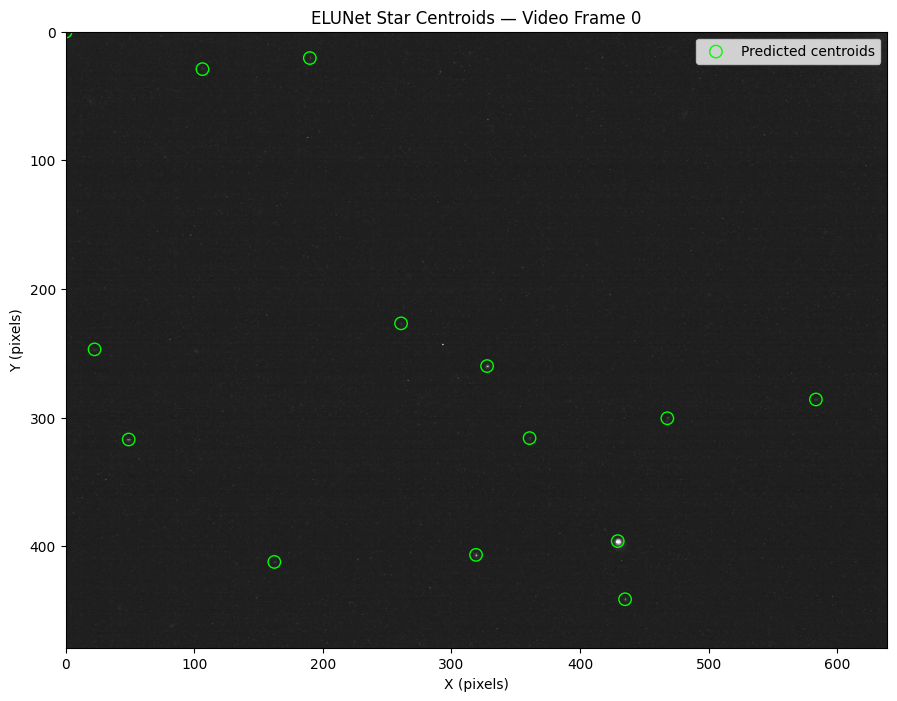

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

# Brighten the dark night-sky frame for display only
plt.imshow(np.clip(frame * 3, 0, 255), cmap="gray", vmin=0, vmax=255)

# Plot predicted centroids
if len(centroids) > 0:
    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        s=80,
        facecolors="none",
        edgecolors="lime",
        label="Predicted centroids"
    )

plt.xlim(0, frame.shape[1] - 1)
plt.ylim(frame.shape[0] - 1, 0)
plt.title("ELUNet Star Centroids — Video Frame 0")
plt.xlabel("X (pixels)")
plt.ylabel("Y (pixels)")
plt.legend()
plt.grid(False)
plt.show()

In [ ]:

import csv
import cv2
import numpy as np
import torch
from pathlib import Path
from torchvision.transforms import Normalize

# ---------- Paths ----------
output_dir = Path(
    "/content/drive/MyDrive/CNNStarDetection/video_results"
)
output_dir.mkdir(parents=True, exist_ok=True)

video_output = output_dir / "video_Test3_ELUNet.mp4"
csv_output = output_dir / "video_Test3_centroids.csv"

# ---------- Model settings ----------
model.eval()
normalize = Normalize(
    mean=[25.36114133],
    std=[44.31162568]
)

radius = 7
pixel_size = 1
fps = 20  # Change this if the original video's frame rate is known

height, width = video.shape[1], video.shape[2]

# MP4 writer
writer = cv2.VideoWriter(
    str(video_output),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not writer.isOpened():
    raise RuntimeError(
        "Could not create the MP4 file. Check the output path and codec."
    )

total_detections = 0

try:
    with open(csv_output, "w", newline="") as csvfile:
        csv_writer = csv.writer(csvfile)
        csv_writer.writerow([
            "frame_index",
            "centroid_index",
            "x_pixel",
            "y_pixel"
        ])

        for i in range(len(video)):
            # Original grayscale frame: 480 x 640
            img = np.array(video[i], dtype=np.float32)

            # Model input: (1, 1, height, width)
            image = torch.from_numpy(img).unsqueeze(0).unsqueeze(0)
            image = image.to(device)

            with torch.no_grad():
                prediction = model(normalize(image))

                seg_prediction = (
                    torch.sigmoid(prediction[0, 0]) > 0.5
                ).float().cpu().numpy()

                dist_prediction = (
                    prediction[0, 1].cpu().numpy()
                )

            # Use the same centroiding method as the official pipeline
            detected = trilateration_centroid_vectorization(
                dist_prediction.copy(),
                seg_prediction.copy(),
                radius,
                pixel_size
            )

            detected = np.asarray(detected, dtype=float).reshape(-1, 2)
            total_detections += len(detected)

            # Write one CSV row per detected centroid
            for j, (x, y) in enumerate(detected):
                csv_writer.writerow([i, j, x, y])

            # Brighten only for video visualization
            display = np.clip(img * 3, 0, 255).astype(np.uint8)
            display = cv2.cvtColor(display, cv2.COLOR_GRAY2BGR)

            # Draw green circles at predicted centroids
            for x, y in detected:
                if np.isfinite(x) and np.isfinite(y):
                    if 0 <= x < width and 0 <= y < height:
                        cv2.circle(
                            display,
                            (int(round(x)), int(round(y))),
                            radius,
                            (0, 255, 0),
                            1
                        )

            writer.write(display)

            if (i + 1) % 50 == 0 or i + 1 == len(video):
                print(
                    f"Processed {i + 1}/{len(video)} frames "
                    f"| detections so far: {total_detections}"
                )

finally:
    writer.release()

print("\nProcessing complete.")
print("Annotated video:", video_output)
print("Centroid CSV:", csv_output)
print("Total frames:", len(video))
print("Total detections:", total_detections)
print("Average detections per frame:", total_detections / len(video))


Processed 50/674 frames | detections so far: 610
Processed 100/674 frames | detections so far: 1236
Processed 150/674 frames | detections so far: 1793
Processed 200/674 frames | detections so far: 2380
Processed 250/674 frames | detections so far: 2918
Processed 300/674 frames | detections so far: 3511
Processed 350/674 frames | detections so far: 4031
Processed 400/674 frames | detections so far: 4517
Processed 450/674 frames | detections so far: 4920
Processed 500/674 frames | detections so far: 5380
Processed 550/674 frames | detections so far: 5871
Processed 600/674 frames | detections so far: 6323
Processed 650/674 frames | detections so far: 6805
Processed 674/674 frames | detections so far: 7013

Processing complete.
Annotated video: /content/drive/MyDrive/CNNStarDetection/video_results/video_Test3_ELUNet.mp4
Centroid CSV: /content/drive/MyDrive/CNNStarDetection/video_results/video_Test3_centroids.csv
Total frames: 674
Total detections: 7013
Average detections per frame: 10.4050

In [ ]:
from pathlib import Path
import cv2
import csv

print("Video exists:", video_output.exists())
print("Video size (MB):", round(video_output.stat().st_size / (1024**2), 2))
print("CSV exists:", csv_output.exists())

cap = cv2.VideoCapture(str(video_output))
print("Output video opened:", cap.isOpened())
print("Output frame count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
cap.release()

with open(csv_output, newline="") as f:
    rows = list(csv.reader(f))

print("CSV data rows:", len(rows) - 1)
print("CSV sample:", rows[:6])

Video exists: True
Video size (MB): 2.48
CSV exists: True
Output video opened: True
Output frame count: 674
CSV data rows: 7013
CSV sample: [['frame_index', 'centroid_index', 'x_pixel', 'y_pixel'], ['0', '0', '189.87075393057057', '20.464497904201927'], ['0', '1', '106.39599542359083', '29.07845979624759'], ['0', '2', '260.81027564745654', '226.76250890138704'], ['0', '3', '22.487868892512687', '247.0037390929629'], ['0', '4', '0.0', '0.0']]


 frame_index  centroid_index    x_pixel     y_pixel
           0               4   0.000000    0.000000
           4               3   0.000000    0.000000
          47               0   0.000000    0.000000
          49               4   0.000000    0.000000
          97               2   0.000000    0.000000
         104               1   0.000000    0.000000
         108               1   0.000000    0.000000
         122               2   0.000000    0.000000
         126               2   0.000000    0.000000
         144               4 -50.282596  150.847787
         156               1   0.000000    0.000000
         164               2   0.000000    0.000000
         175               0   0.000000    0.000000
         186               2   0.000000    0.000000
         200               3   0.000000    0.000000
         206               5   0.000000    0.000000
         208               1   0.000000    0.000000
         220               2   0.000000    0.000000
         234

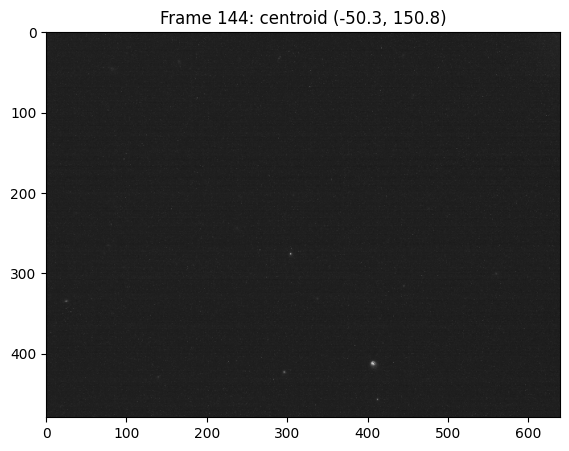

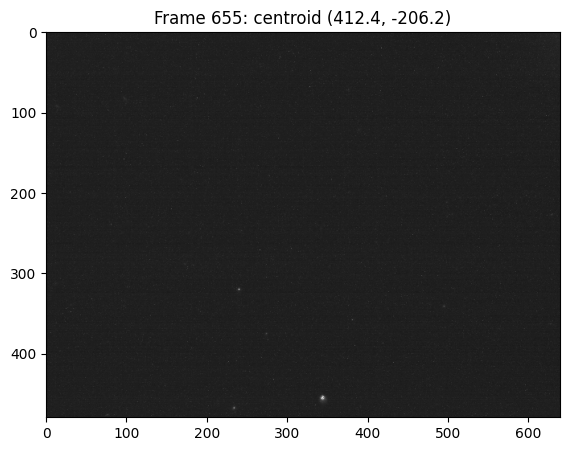

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(csv_output)

suspects = df[
    ((df["x_pixel"] == 0) & (df["y_pixel"] == 0)) |
    (df["x_pixel"] < 0) |
    (df["x_pixel"] >= 640) |
    (df["y_pixel"] < 0) |
    (df["y_pixel"] >= 480)
]

print(suspects.to_string(index=False))

# Visualize the two out-of-frame detections on their corresponding frames
for _, row in suspects[
    (suspects["x_pixel"] < 0) |
    (suspects["x_pixel"] >= 640) |
    (suspects["y_pixel"] < 0) |
    (suspects["y_pixel"] >= 480)
].iterrows():

    frame_idx = int(row["frame_index"])
    img = np.asarray(video[frame_idx])

    plt.figure(figsize=(10, 5))
    plt.imshow(np.clip(img * 3, 0, 255), cmap="gray", vmin=0, vmax=255)
    plt.title(
        f"Frame {frame_idx}: "
        f"centroid ({row['x_pixel']:.1f}, {row['y_pixel']:.1f})"
    )
    plt.xlim(0, 639)
    plt.ylim(479, 0)
    plt.show()

In [ ]:
from google.colab import files

files.download(
    "/content/CNNProject-StarDetectionReproduction/hardware_experiment/saved_results/video_Test3.npy"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Test images found: 100
Selected file: raw_image_1.npy
Image shape: (480, 640)
Minimum pixel value: 12.0
Maximum pixel value: 82.0
PNG saved to: /content/CNNProject-StarDetectionReproduction/test_images/generated_test_image.png


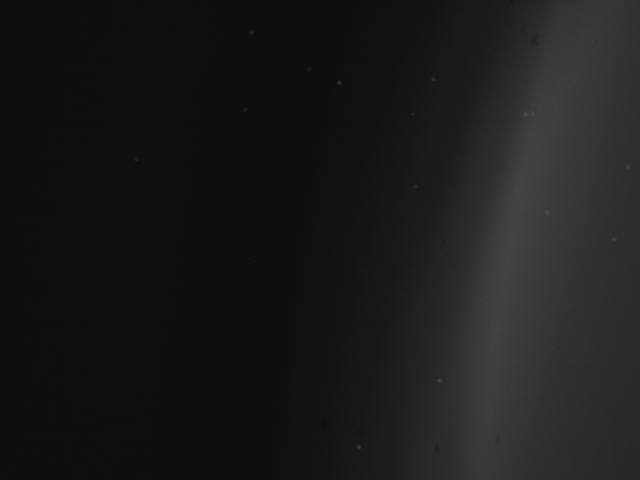

In [ ]:

from pathlib import Path
import numpy as np
from PIL import Image
from IPython.display import display

repo = Path("/content/CNNProject-StarDetectionReproduction")
test_dir = repo / "data_generation" / "training_data" / "test_raw"

# Find generated test images.
files = sorted(test_dir.glob("*.npy"))

print("Test images found:", len(files))

if not files:
    print("No test images found. Check whether the dataset was generated.")
else:
    source = files[1]
    image = np.load(source)

    print("Selected file:", source.name)
    print("Image shape:", image.shape)
    print("Minimum pixel value:", image.min())
    print("Maximum pixel value:", image.max())

    # Export without rescaling the original intensity range.
    if image.ndim != 2:
        raise ValueError(f"Expected a grayscale 2D image, got {image.shape}")

    if image.min() < 0 or image.max() > 255:
        raise ValueError(
            "Pixel values are outside the 0–255 range. "
            "Inspect the printed values before converting to PNG."
        )

    output_dir = repo / "test_images"
    output_dir.mkdir(exist_ok=True)
    output_path = output_dir / "generated_test_image.png"

    Image.fromarray(np.rint(image).astype(np.uint8)).save(output_path)

    print("PNG saved to:", output_path)
    display(Image.open(output_path))
